# Chain parity and interaction range
This notebook was prepared with AI assistance. It uses worked examples and both odd and even chain lengths to ask: **how do parity and open ends affect interaction-truncation errors in small Rydberg chains?** A kagome patch comparison is included as an optional extension.

Run from the `study` folder. Small examples are recomputed; the larger scan is read from saved CSVs. No cell reruns the full scan or writes the supplied data. `python run_project.py --section chains` creates a separate completed run.

Use $g=V_0/\Omega$, $\delta=\Delta/\Omega$, and $\Delta t$ for a time step. The examples explain the distinction between excitation imbalance $M^2$ and the parity-normalised spin diagnostic $S^2$. See the [results and limitations](../docs/RESULTS_AND_LIMITS.md) for the scope of the numerical evidence.


In [1]:
from pathlib import Path
import csv, json, sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from extension_model import ground_point, chain_couplings, discarded_tail_bound
import rydberg_model as model
import kagome_pilot as kagome
%matplotlib inline
ROOT = Path.cwd()
assert (ROOT / 'results/extension_summary.json').exists()
def read_rows(name):
    with (ROOT / 'results' / name).open() as f:
        return list(csv.DictReader(f))
print('Python:', sys.version.split()[0])
print('Ground-state examples and saved numerical comparisons.')

Python: 3.12.14
Ground-state examples and saved numerical comparisons.


## 1 Count the interactions before constructing the matrix
Four atoms have six pairs. Nearest neighbours are 01, 12, 23; second neighbours are 02, 13; the last pair is 03. With $g=8$, a second-neighbour coupling is $8/2^6=0.125$.

**Predict:** which entries of each coupling matrix below should be zero? All three models keep the same number of atoms and the same laser.

In [2]:
for cutoff in ['nearest1', 'nearest2', 'all']:
    coupling = chain_couplings(4, 8, cutoff)
    print(cutoff, '\n', np.round(coupling, 5))
assert chain_couplings(4, 8, 'nearest2')[0, 2] == 0.125
assert chain_couplings(4, 8, 'nearest1')[0, 2] == 0

nearest1 
 [[0. 8. 0. 0.]
 [8. 0. 8. 0.]
 [0. 8. 0. 8.]
 [0. 0. 8. 0.]]
nearest2 
 [[0.    8.    0.125 0.   ]
 [8.    0.    8.    0.125]
 [0.125 8.    0.    8.   ]
 [0.    0.125 8.    0.   ]]
all 
 [[0.      8.      0.125   0.01097]
 [8.      0.      8.      0.125  ]
 [0.125   8.      0.      8.     ]
 [0.01097 0.125   8.      0.     ]]


## 2 Check a matrix that you can build by hand
For two atoms, use the ordered basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$. The diagonal is $0,-\delta,-\delta,g-2\delta$. A laser flip contributes $1/2$ to each allowed off-diagonal entry. The lowest eigenvalue of this matrix is the ground-state energy.

In [3]:
delta, g = 0.4, 5.0
hand = np.array([[0, .5, .5, 0],
                 [.5, -delta, 0, .5],
                 [.5, 0, -delta, .5],
                 [0, .5, .5, g - 2*delta]])
general = model.hamiltonian(chain_couplings(2, g), delta=delta).toarray()
assert np.allclose(hand, general, atol=1e-13)
energies, vectors = eigh(hand)
print('Hand-built matrix agrees. Energies:', energies)
print('Ground-state probabilities:', np.round(abs(vectors[:, 0])**2, 6))

Hand-built matrix agrees. Energies: [-0.99746925 -0.4         0.48860381  4.30886544]
Ground-state probabilities: [0.330391 0.32872  0.32872  0.012169]


## 3 An analytic control with no interactions
The one-atom ground-state excitation probability is
$p=[1+\delta/\sqrt{1+\delta^2}]/2$.
When $g=0$, every atom has this probability. This is a check against a known answer, rather than a comparison of two plots made from the same code.

**Predict:** the answers at $\delta=-1,0,1$, and whether changing $N$ should change them.

In [4]:
for delta in [-1.0, 0.0, 1.0]:
    row, local, _ = ground_point(4, 0, delta)
    analytic = (1 + delta/np.sqrt(1 + delta**2))/2
    assert abs(row['density'] - analytic) < 1e-11
    assert np.allclose(local, analytic, atol=1e-11)
    print(f'delta={delta:+g}: density={row["density"]:.8f}, analytic={analytic:.8f}')

delta=-1: density=0.14644661, analytic=0.14644661
delta=+0: density=0.50000000, analytic=0.50000000
delta=+1: density=0.85355339, analytic=0.85355339


## 4 Recompute a controlled comparison
At $N=6$, $g=8$ and $\delta=2$, find a new ground state for each interaction range. Keep the parameter settings fixed. The ground state changes when the Hamiltonian changes, so reusing one state for all models would not answer our question.

The `residual` is $\|H\psi-E\psi\|$. It should be small if the returned vector satisfies its eigenvalue equation.

In [5]:
examples = {}
for cutoff in ['nearest1', 'nearest2', 'all']:
    row, local, matrix = ground_point(6, 8, 2, cutoff)
    examples[cutoff] = (row, local)
    assert row['residual'] < 1e-7
    print(cutoff, {key: round(row[key], 8)
                   for key in ['density', 'alternating_order_squared', 'gap']})
full_density = examples['all'][0]['density']
for cutoff in ['nearest1', 'nearest2']:
    error = abs(examples[cutoff][0]['density'] - full_density)
    print(cutoff, 'absolute density error:', error, 'percentage points:', 100*error)

nearest1 {'density': 0.46645575, 'alternating_order_squared': 0.32575052, 'gap': 0.17164136}
nearest2 {'density': 0.46401457, 'alternating_order_squared': 0.24549841, 'gap': 0.22558899}
all {'density': 0.46373906, 'alternating_order_squared': 0.25023504, 'gap': 0.22277997}
nearest1 absolute density error: 0.002716683650203444 percentage points: 0.2716683650203444
nearest2 absolute density error: 0.0002755100204641092 percentage points: 0.027551002046410922


## 5 The average can hide the positions
Draw each site's excitation probability for the freshly calculated example. The mean of the six values is the density printed above. Open endpoints have fewer neighbours, so they are not equivalent to the middle sites. This plot diagnoses spatial variation; it does not isolate a thermodynamic bulk limit.

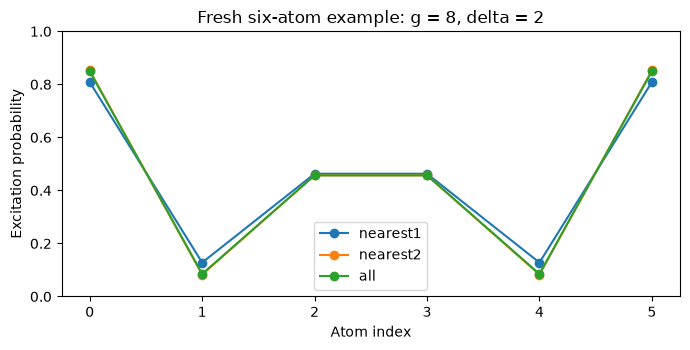

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for cutoff, (row, local) in examples.items():
    ax.plot(range(6), local, 'o-', label=cutoff)
ax.set(xlabel='Atom index', ylabel='Excitation probability',
       title='Fresh six-atom example: g = 8, delta = 2', ylim=(0, 1))
ax.legend(); fig.tight_layout(); plt.show()

## 6 Read the full saved chain scan
These cells read 6,561 coarse-grid ground states: nine lengths N=4 through 12, three strengths, 81 detunings and three interaction ranges. Extra local refinement points are stored separately. No cell reruns this full grid.

The g=2 scan is a weaker-interaction comparison. Do not assume it describes the same blockade-dominated regime as g=8 and 16 throughout the detuning interval.

In [7]:
scan = read_rows('ground_states_coarse.csv')
print('Stored chain rows:', len(scan))
assert len(scan) == 9*3*81*3
def curve(number, strength, cutoff, key='density'):
    selected = [r for r in scan if int(r['N']) == number
                and float(r['g']) == strength and r['cutoff'] == cutoff]
    selected.sort(key=lambda r: float(r['delta']))
    return (np.array([float(r['delta']) for r in selected]),
            np.array([float(r[key]) for r in selected]))
print('Example row:', scan[0])

Stored chain rows: 6561
Example row: {'N': '4', 'g': '2.0', 'delta': '-3.0', 'cutoff': 'nearest1', 'density': '0.024824804991391534', 'alternating_order_squared': '0.024587473190740262', 'staggered_spin_squared': '0.024587473190740262', 'staggered_spin_mean': '-6.938893903907228e-18', 'gap': '3.160637933369335', 'ground_energy': '-0.3216303270476708', 'centre_density': '0.024548795069871846', 'edge_density': '0.025100814912911214', 'residual': '4.436153710619907e-15', 'relative_residual': '1.1555469969152773e-15', 'orthogonality_error': '0.0', 'normalization_error': '2.220446049250313e-16'}


## 7 Compare odd and even chains separately
At g=8, plot the density error in percentage points. Connecting all sizes into one trend hides the parity dependence. A larger N is not automatically closer to an infinite-chain answer.

Predict how the two panels will differ before running. The curves alone do not distinguish every mechanism; the bitstring and gap controls below examine a selected point.

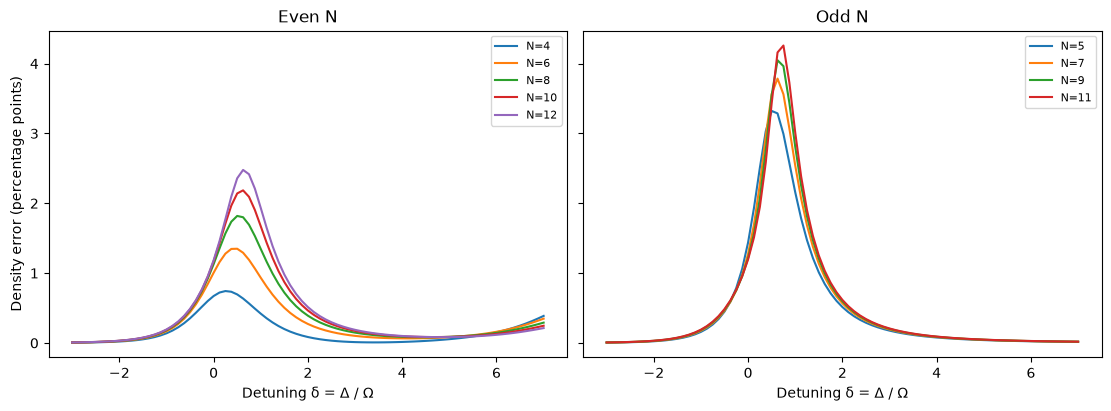

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, sizes, title in zip(axes, [[4,6,8,10,12], [5,7,9,11]], ['Even N', 'Odd N']):
    for number in sizes:
        delta, near = curve(number, 8, 'nearest1')
        _, full = curve(number, 8, 'all')
        ax.plot(delta, 100*abs(near-full), label=f'N={number}')
    ax.set(xlabel='Detuning δ = Δ / Ω', title=title)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Density error (percentage points)')
plt.show()

## 8 Keeping second neighbours
Compare N=11 and 12 at the same strengths. This includes both parities. Differences between each truncated model and the full model are evaluated at matching parameters. These plots use the coarse grid; refined sampled maxima are in maximum_errors.csv.

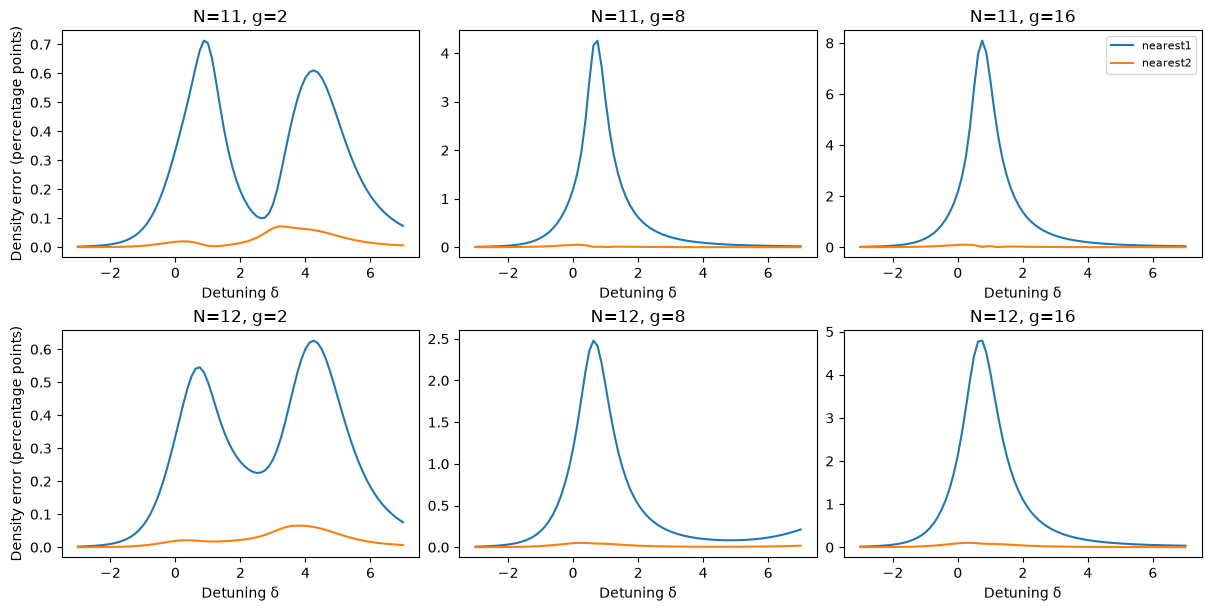

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
for row_axes, number in zip(axes, [11, 12]):
    for ax, strength in zip(row_axes, [2, 8, 16]):
        delta, full = curve(number, strength, 'all')
        for cutoff in ['nearest1', 'nearest2']:
            _, cut = curve(number, strength, cutoff)
            ax.plot(delta, 100*abs(cut-full), label=cutoff)
        ax.set(title=f'N={number}, g={strength}', xlabel='Detuning δ')
    row_axes[0].set_ylabel('Density error (percentage points)')
axes[0,-1].legend(fontsize=8); plt.show()

## 9 A bound you can calculate by hand
For an $N$-atom open chain, there are $N-r$ pairs separated by $r$ spacings. The largest possible total discarded interaction is
$B=g\sum_{r=R+1}^{N-1}(N-r)/r^6$.
Every pair contribution is nonnegative and at most its coupling strength. The all-excited basis state attains the maximum simultaneously.

Therefore $0\le E_k^{\mathrm{all}}-E_k^R\le B$ and $|G^{\mathrm{all}}-G^R|\le B$. This bound controls **energy changes**, not density error. For four atoms with $g=8$, dropping all but nearest neighbours gives $B=8(2/64+1/729)$.

In [10]:
hand_bound = 8*(2/64 + 1/729)
assert np.isclose(hand_bound, discarded_tail_bound(4, 8, 'nearest1'))
print('Four-atom hand bound:', hand_bound)
for cutoff in ['nearest1', 'nearest2']:
    cut, _, _ = ground_point(6, 8, 2, cutoff)
    full, _, _ = ground_point(6, 8, 2, 'all')
    bound = discarded_tail_bound(6, 8, cutoff)
    energy_shift = full['ground_energy'] - cut['ground_energy']
    assert -1e-10 <= energy_shift <= bound + 1e-10
    assert abs(full['gap']-cut['gap']) <= bound + 1e-10
    print(cutoff, 'energy shift:', energy_shift, 'upper bound:', bound)

Four-atom hand bound: 0.2609739368998628
nearest1 energy shift: 0.1398907032473975 upper bound: 0.5373400606995885
nearest2 energy shift: 0.008356233313492112 upper bound: 0.03734006069958848


## Check parity with configurations
A bitstring represents one possible measurement outcome, not the complete ground state. At g=8 and δ=3, compare the five most likely strings for N=8 and 9. Atom 0 is on the right.

Compute both diagnostics for the ideal strings first. Explain why the old $M^2$ can exceed one at odd N without any probability exceeding one. A string containing a 00 bond breaks the alternating pattern; this differs from an experimentally missing atom.

In [11]:
for number in [8, 9]:
    bits = model.occupations(number)
    signs = (-1.)**np.arange(number)
    old = (2/number)*(bits @ signs)
    spin = (2*bits-1) @ signs / number
    alternating_indices = [sum(int((i+shift)%2)*2**i for i in range(number)) for shift in [0,1]]
    print('N',number,'ideal M²',old[alternating_indices]**2,'ideal S²',spin[alternating_indices]**2)
    assert np.allclose(spin[alternating_indices]**2,1)
    H = model.hamiltonian(chain_couplings(number,8,'all'),delta=3)
    energies, vectors = eigh(H.toarray(),subset_by_index=[0,1])
    probabilities = abs(vectors[:,0])**2
    print('Gap:',energies[1]-energies[0], 'M²:', probabilities @ old**2, 'S²:', probabilities @ spin**2)
    for index in np.argsort(probabilities)[-5:][::-1]:
        print(format(index,f'0{number}b'),round(probabilities[index],6))
    print('Total weight of the two perfect patterns:',probabilities[alternating_indices].sum())

N 8 ideal M² [1. 1.] ideal S² [1. 1.]
Gap: 0.13685670548623108 M²: 0.20098933162082683 S²: 0.20098933162082683
10100101 0.329331
10010101 0.217832
10101001 0.217832
10101010 0.031745
01010101 0.031745
Total weight of the two perfect patterns: 0.06349089397052873
N 9 ideal M² [0.79012346 1.2345679 ] ideal S² [1. 1.]
Gap: 2.3223898489929553 M²: 1.1652539174333625 S²: 0.9385253011313728
101010101 0.852863
101000101 0.027304
101010001 0.027267
100010101 0.027267
101010100 0.024703
Total weight of the two perfect patterns: 0.8528625456458239


The parity effect is substantial at this selected point. A small even-chain gap need not be the splitting of only two ideal alternating strings or a bulk transition. Read the [results and limitations](../docs/RESULTS_AND_LIMITS.md) for ground- and excited-state projections onto the domain-wall configurations. This finite example does not identify the mechanism of every small gap throughout the scan.

## Optional appendix on a twelve atom Kagome patch
The kagome patch uses primitive vectors $(2,0)$ and $(1,\sqrt3)$ and three sites per unit cell: $(0,0)$, $(1,0)$ and $(1/2,\sqrt3/2)$. Two cells in each direction give twelve sites. The patch is open.

These atoms are on kagome **sites**. They are not placed on kagome links, as in the ruby geometry used in another spin-liquid experiment. The grey lines below identify nearest-neighbour geometry; the all-pair model also includes interactions between dots without a drawn line.

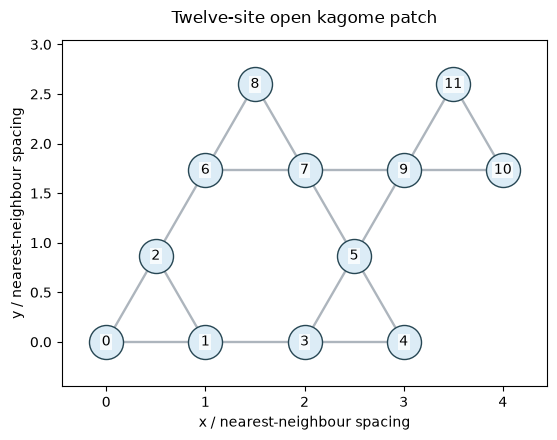

Nearest neighbours per atom: [2, 3, 3, 3, 2, 4, 3, 4, 2, 4, 2, 2]


In [12]:
positions = kagome.kagome_sites()
bonds = kagome.nearest_bonds(positions)
assert positions.shape == (12, 2) and len(bonds) == 17
fig, ax = plt.subplots(figsize=(6.4, 4.5))
kagome.plot_geometry(ax, positions, bonds, title='Twelve-site open kagome patch')
fig.tight_layout(); plt.show()
print('Nearest neighbours per atom:', [sum(i in pair for pair in bonds) for i in range(12)])

## 11 Recompute one kagome example
This cell independently reruns the two interaction models at $g=8$, $\delta=2$. For basis probabilities $|c_b|^2$, each site's probability is a weighted sum of its 0/1 occupations. The connected correlation is
$C_{ij}=\langle n_i n_j\rangle-\langle n_i\rangle\langle n_j\rangle$.
It removes the part expected if the two measurements were independent. It is not by itself an entanglement measure.

In [13]:
occupied = model.occupations(12)
kagome_examples = {}
for name, coupling in kagome.coupling_models(positions).items():
    matrix = model.hamiltonian(coupling, delta=2.0)
    energies, vectors, residuals = kagome.lowest_pair(matrix, seed=230923)
    assert max(residuals) < 1e-8
    local, connected, nn_mean = kagome.observables(vectors[:, 0], occupied, bonds)
    kagome_examples[name] = (vectors[:, 0], local, connected)
    print(name, 'mean density:', local.mean(), 'site 0:', local[0],
          'gap:', energies[1]-energies[0])

nearest_only mean density: 0.3054643189570982 site 0: 0.5209684459289986 gap: 0.29253706924495226


all_pairs mean density: 0.3024891164495127 site 0: 0.6549124632251476 gap: 0.335529520401618


## 12 Compare the whole mean with a local change
Use the same colour scale in both plots. A small change in their means can hide a larger redistribution between positions. The patch is strongly affected by its boundaries: these are not infinite-kagome site probabilities.

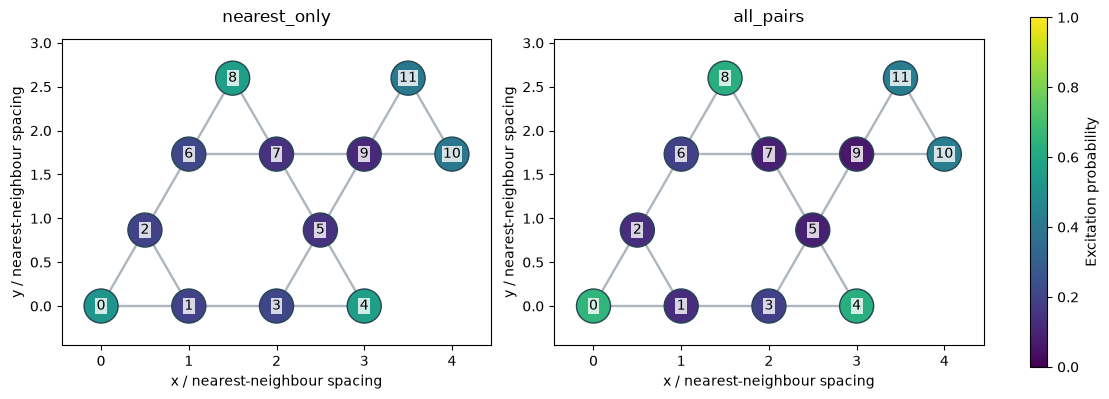

Mean density change in percentage points: -0.2975202507585484
Site 0 change in percentage points: 13.394401729614902


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, (name, (state, local, connected)) in zip(axes, kagome_examples.items()):
    artist = kagome.plot_geometry(ax, positions, bonds, values=local, title=name)
fig.colorbar(artist, ax=axes, label='Excitation probability', shrink=.85)
plt.show()
near = kagome_examples['nearest_only'][1]
full = kagome_examples['all_pairs'][1]
print('Mean density change in percentage points:', 100*(full.mean()-near.mean()))
print('Site 0 change in percentage points:', 100*(full[0]-near[0]))

## 13 Count excitations on a triangle
The triangle labelled 5, 7, 9 lies inside this drawn patch. Add its three occupation bits in every basis state, then sum basis-state probabilities for totals 0, 1, 2 and 3.

**Predict:** repulsion should suppress multiple excitations on a triangle. Does that force every triangle to contain exactly one excitation? The answer is something we can test.

nearest_only {0: np.float64(0.5984187249343491), 1: np.float64(0.3998710657129518), 2: np.float64(0.0017092738348032654), 3: np.float64(9.355178960510444e-07)}
all_pairs {0: np.float64(0.7651196434100089), 1: np.float64(0.233878491224627), 2: np.float64(0.0010013075303250572), 3: np.float64(5.578350364967726e-07)}


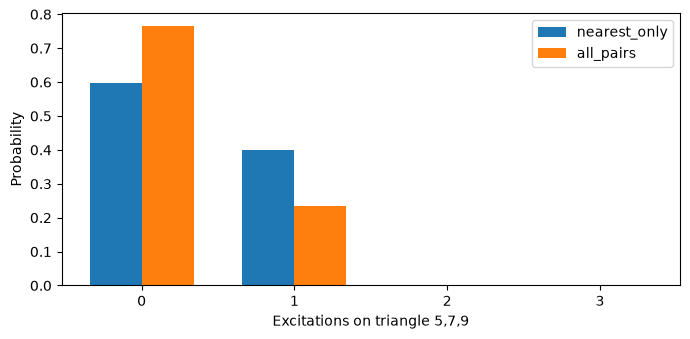

In [15]:
triangle = [5, 7, 9]
counts = occupied[:, triangle].sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 3.5))
for offset, (name, (state, local, connected)) in zip([-.17, .17], kagome_examples.items()):
    weights = abs(state)**2
    probabilities = np.array([weights[counts == k].sum() for k in range(4)])
    assert abs(probabilities.sum()-1) < 1e-10
    ax.bar(np.arange(4)+offset, probabilities, width=.34, label=name)
    print(name, dict(zip(range(4), probabilities)))
ax.set(xticks=range(4), xlabel='Excitations on triangle 5,7,9', ylabel='Probability')
ax.legend(); fig.tight_layout(); plt.show()

## Check your understanding
1. What exactly changed between the three chain models?
2. Why did we use percentage-point density differences rather than relative errors?
3. What does the analytic tail bound guarantee, and what does it not guarantee?
4. Why can an accurate mean density hide an inaccurate local probability?
5. Why is this kagome result not evidence of a quantum spin liquid?

Read the [results and limitations](../docs/RESULTS_AND_LIMITS.md) for the scan interpretation, numerical checks and additional kagome shape control. Record your own predictions and reasoning when reproducing or extending the calculations. The finite kagome patch is not evidence about a bulk quantum spin-liquid phase.
